In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score

# Load the dataset
df = pd.read_csv("Mall_Customers.csv")

# Display the first five rows
print(df.head())

# Display dataset dimensions
print("Dataset shape:", df.shape)

# Check column names and data types
df.info()

# Generate descriptive statistics
print(df.describe(include="all"))

   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                      77
4           5  Female   31                  17                      40
Dataset shape: (200, 5)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB
        CustomerID  Gender      

In [2]:
# Check for missing values
print(df.isnull().sum())

# Check for duplicate records
print("Duplicate rows:", df.duplicated().sum())

# Remove exact duplicate rows if any
df = df.drop_duplicates().copy()

# Select the clustering features
features = [
    "Annual Income (k$)",
    "Spending Score (1-100)"
]

# Keep rows with valid values in the selected features
df = df.dropna(subset=features).copy()

# Create the feature matrix
X = df[features]

print("Cleaned dataset shape:", df.shape)
print(X.head())

CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64
Duplicate rows: 0
Cleaned dataset shape: (200, 5)
   Annual Income (k$)  Spending Score (1-100)
0                  15                      39
1                  15                      81
2                  16                       6
3                  16                      77
4                  17                      40


In [3]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Scaled data shape:", X_scaled.shape)

Scaled data shape: (200, 2)


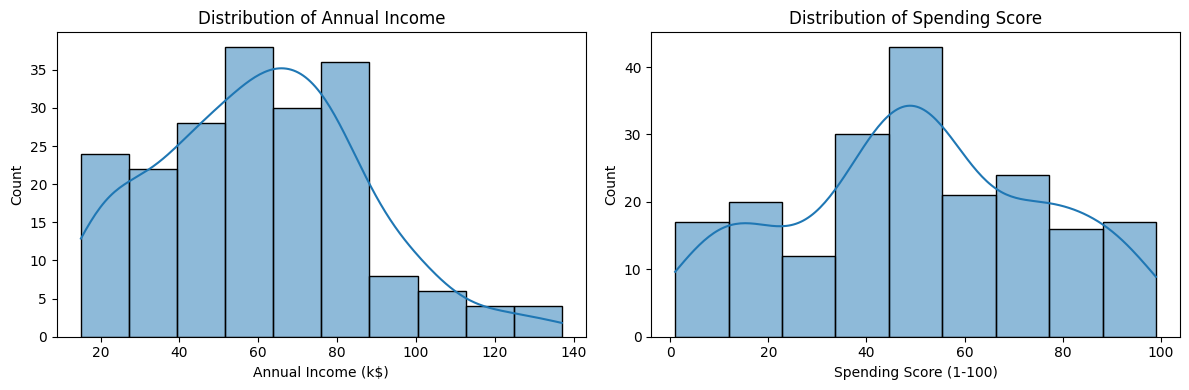

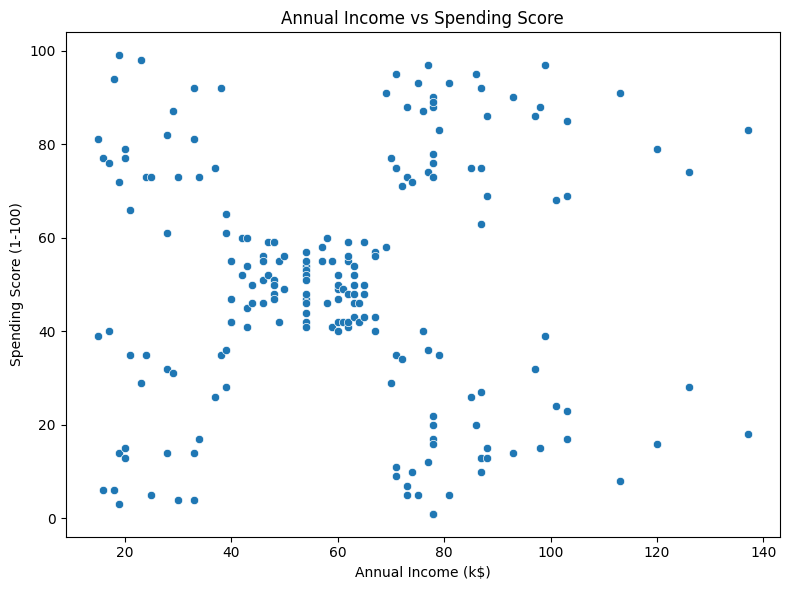

In [4]:
# Histograms for the selected features
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(df["Annual Income (k$)"], kde=True, ax=axes[0])
axes[0].set_title("Distribution of Annual Income")

sns.histplot(df["Spending Score (1-100)"], kde=True, ax=axes[1])
axes[1].set_title("Distribution of Spending Score")

plt.tight_layout()
plt.show()

# Relationship between income and spending
plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=df,
    x="Annual Income (k$)",
    y="Spending Score (1-100)"
)
plt.title("Annual Income vs Spending Score")
plt.tight_layout()
plt.show()

   Number of Clusters  Inertia  Silhouette Score
0                   2  269.691             0.321
1                   3  157.704             0.467
2                   4  108.921             0.494
3                   5   65.568             0.555
4                   6   55.057             0.540
5                   7   44.865             0.528
6                   8   37.148             0.457


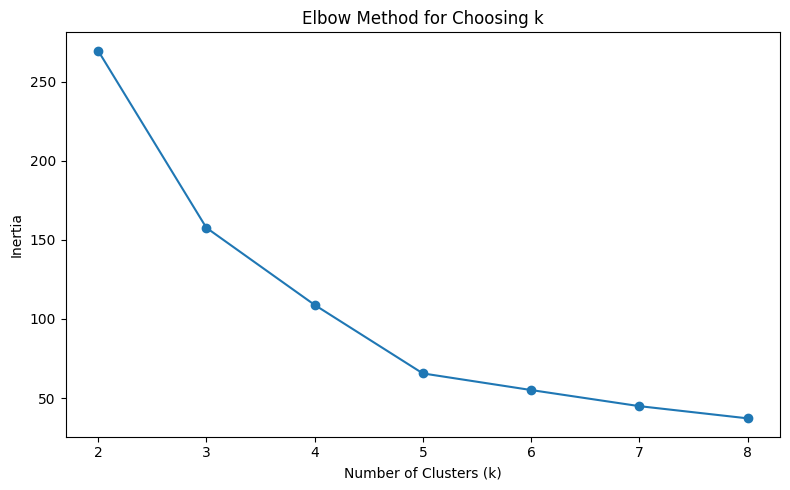

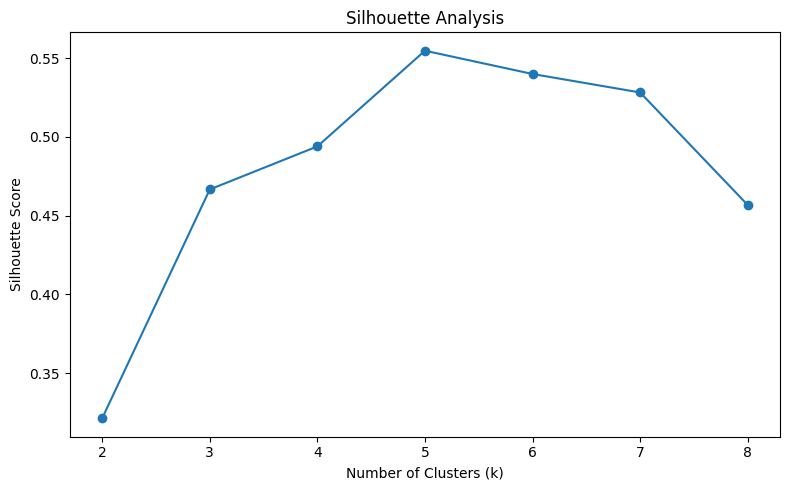

In [5]:
# Test different numbers of clusters
k_values = range(2, 9)

inertias = []
silhouette_scores = []

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )

    labels = model.fit_predict(X_scaled)

    inertias.append(model.inertia_)
    silhouette_scores.append(
        silhouette_score(X_scaled, labels)
    )

# Print the evaluation table
evaluation = pd.DataFrame({
    "Number of Clusters": list(k_values),
    "Inertia": inertias,
    "Silhouette Score": silhouette_scores
})

print(evaluation.round(3))

# Plot the elbow curve
plt.figure(figsize=(8, 5))
plt.plot(list(k_values), inertias, marker="o")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.title("Elbow Method for Choosing k")
plt.xticks(list(k_values))
plt.tight_layout()
plt.show()

# Plot silhouette scores
plt.figure(figsize=(8, 5))
plt.plot(list(k_values), silhouette_scores, marker="o")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Analysis")
plt.xticks(list(k_values))
plt.tight_layout()
plt.show()

In [6]:
chosen_k = 5

kmeans = KMeans(
    n_clusters=chosen_k,
    random_state=42,
    n_init=20
)

# Assign a cluster to each customer
df["Cluster"] = kmeans.fit_predict(X_scaled)

# Calculate the silhouette score
final_silhouette = silhouette_score(
    X_scaled,
    df["Cluster"]
)

print("Chosen number of clusters:", chosen_k)
print("Final silhouette score:", round(final_silhouette, 3))

# Display cluster counts
print(df["Cluster"].value_counts().sort_index())

Chosen number of clusters: 5
Final silhouette score: 0.555
Cluster
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64


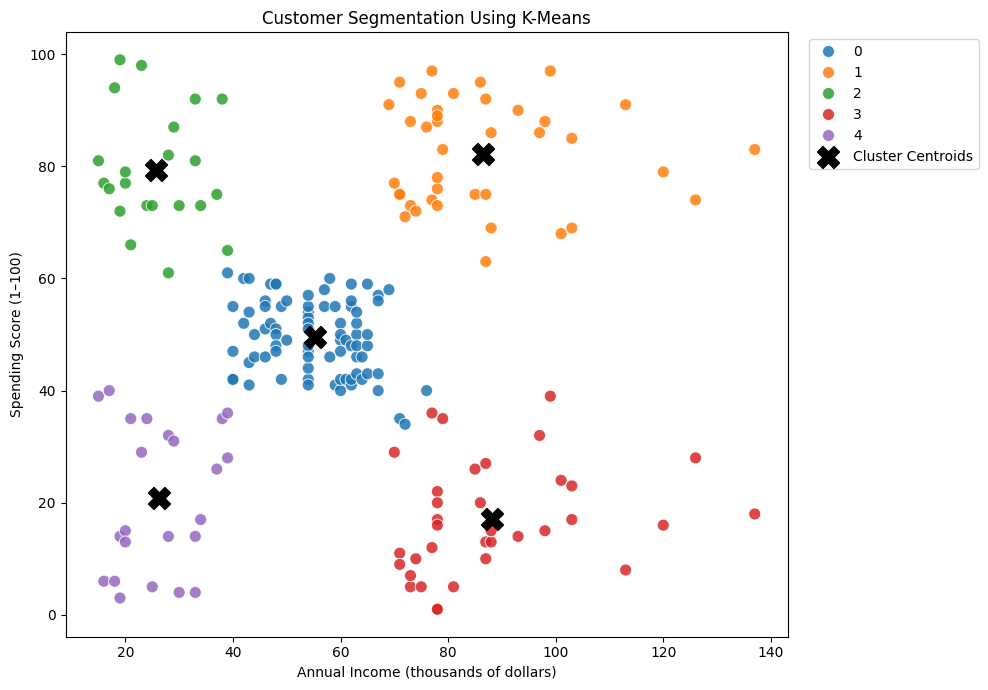

In [7]:
# Convert cluster centers back to the original feature scales
centers = scaler.inverse_transform(kmeans.cluster_centers_)

plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=df,
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    hue="Cluster",
    palette="tab10",
    s=75,
    alpha=0.85
)

plt.scatter(
    centers[:, 0],
    centers[:, 1],
    marker="X",
    s=250,
    color="black",
    label="Cluster Centroids"
)

plt.title("Customer Segmentation Using K-Means")
plt.xlabel("Annual Income (thousands of dollars)")
plt.ylabel("Spending Score (1–100)")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

In [8]:
# Calculate the size and average characteristics of each segment
profile = df.groupby("Cluster").agg(
    Customer_Count=("CustomerID", "count"),
    Average_Age=("Age", "mean"),
    Average_Income=("Annual Income (k$)", "mean"),
    Average_Spending=("Spending Score (1-100)", "mean")
).round(2)

profile["Customer_Percentage"] = (
    profile["Customer_Count"] / len(df) * 100
).round(2)

print("Cluster Profile:")
print(profile)

# Examine the gender distribution in each cluster
gender_distribution = pd.crosstab(
    df["Cluster"],
    df["Gender"],
    normalize="index"
).mul(100).round(1)

print("\nGender Distribution (%):")
print(gender_distribution)

Cluster Profile:
         Customer_Count  Average_Age  Average_Income  Average_Spending  \
Cluster                                                                  
0                    81        42.72           55.30             49.52   
1                    39        32.69           86.54             82.13   
2                    22        25.27           25.73             79.36   
3                    35        41.11           88.20             17.11   
4                    23        45.22           26.30             20.91   

         Customer_Percentage  
Cluster                       
0                       40.5  
1                       19.5  
2                       11.0  
3                       17.5  
4                       11.5  

Gender Distribution (%):
Gender   Female  Male
Cluster              
0          59.3  40.7
1          53.8  46.2
2          59.1  40.9
3          45.7  54.3
4          60.9  39.1


In [9]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score

hierarchical = AgglomerativeClustering(
    n_clusters=chosen_k,
    linkage="ward"
)

hierarchical_labels = hierarchical.fit_predict(X_scaled)

hierarchical_silhouette = silhouette_score(
    X_scaled,
    hierarchical_labels
)

print(
    "K-Means silhouette:",
    round(final_silhouette, 3)
)

print(
    "Hierarchical silhouette:",
    round(hierarchical_silhouette, 3)
)

K-Means silhouette: 0.555
Hierarchical silhouette: 0.554
